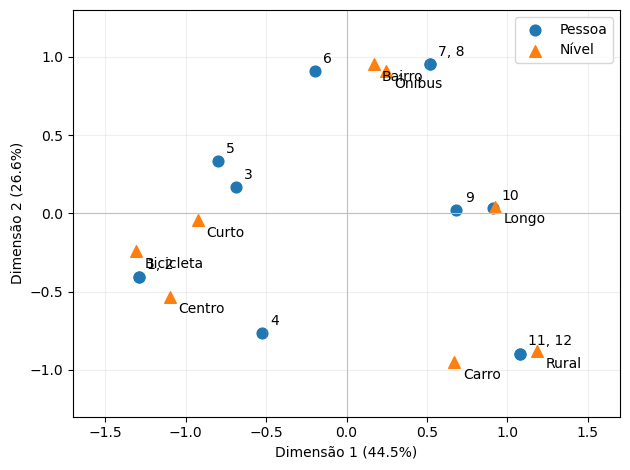

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Z = np.array([
    [1, 0, 0, 0, 0, 1, 1, 0],
    [1, 0, 0, 0, 0, 1, 1, 0],
    [1, 0, 0, 0, 1, 0, 1, 0],
    [1, 0, 0, 1, 0, 0, 1, 0],
    [0, 1, 0, 0, 0, 1, 1, 0],
    [0, 1, 0, 0, 1, 0, 1, 0],
    [0, 1, 0, 0, 1, 0, 0, 1],
    [0, 1, 0, 0, 1, 0, 0, 1],
    [0, 1, 0, 1, 0, 0, 0, 1],
    [0, 0, 1, 0, 1, 0, 0, 1],
    [0, 0, 1, 1, 0, 0, 0, 1],
    [0, 0, 1, 1, 0, 0, 0, 1],
], dtype=float)

niveis = ["Centro", "Bairro", "Rural", "Carro", "Ônibus", "Bicicleta", "Curto", "Longo"]
n, Q = Z.shape[0], 3

P_acm = Z / Z.sum()
r_acm = P_acm.sum(axis=1)
c_acm = P_acm.sum(axis=0)
S_acm = np.diag(1 / np.sqrt(r_acm)) @ (P_acm - np.outer(r_acm, c_acm)) @ np.diag(1 / np.sqrt(c_acm))

U_acm, lam_acm, Vt_acm = np.linalg.svd(S_acm, full_matrices=False)
tol = np.finfo(float).eps * max(S_acm.shape) * lam_acm[0]
lam_acm = lam_acm[lam_acm > tol]
K = len(lam_acm)

F_acm = np.diag(1 / np.sqrt(r_acm)) @ U_acm[:, :K] @ np.diag(lam_acm)
G_acm = np.diag(1 / np.sqrt(c_acm)) @ Vt_acm.T[:, :K] @ np.diag(lam_acm)
explicada = lam_acm**2 / np.sum(lam_acm**2)

fig, ax = plt.subplots()
ax.scatter(F_acm[:, 0], F_acm[:, 1], marker="o", s=60, label="Pessoa")
ax.scatter(G_acm[:, 0], G_acm[:, 1], marker="^", s=70, label="Nível")

# Pessoas com as mesmas respostas caem no mesmo ponto e dividem um rótulo
rotulos_pessoa = {}
for i, (x, y) in enumerate(F_acm[:, :2].round(6), start=1):
    rotulos_pessoa.setdefault((x, y), []).append(str(i))
for (x, y), ids in rotulos_pessoa.items():
    ax.annotate(", ".join(ids), (x, y), xytext=(6, 6), textcoords="offset points")

for rotulo, (x, y) in zip(niveis, G_acm[:, :2]):
    ax.annotate(rotulo, (x, y), xytext=(6, -12), textcoords="offset points")

ax.axhline(0, color="0.75", linewidth=0.8)
ax.axvline(0, color="0.75", linewidth=0.8)
ax.set_xlabel(f"Dimensão 1 ({explicada[0]:.1%})")
ax.set_ylabel(f"Dimensão 2 ({explicada[1]:.1%})")
ax.set_xlim(-1.7, 1.7)
ax.set_ylim(-1.3, 1.3)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
c_acm

array([0.11111111, 0.13888889, 0.08333333, 0.11111111, 0.13888889,
       0.08333333, 0.16666667, 0.16666667])

In [12]:
12*(3*(1/36 * 12 - 1/12)**2 + 9*(-1/12)**2)

3.0

In [6]:
P_acm

array([[0.02777778, 0.        , 0.        , 0.        , 0.        ,
        0.02777778, 0.02777778, 0.        ],
       [0.02777778, 0.        , 0.        , 0.        , 0.        ,
        0.02777778, 0.02777778, 0.        ],
       [0.02777778, 0.        , 0.        , 0.        , 0.02777778,
        0.        , 0.02777778, 0.        ],
       [0.02777778, 0.        , 0.        , 0.02777778, 0.        ,
        0.        , 0.02777778, 0.        ],
       [0.        , 0.02777778, 0.        , 0.        , 0.        ,
        0.02777778, 0.02777778, 0.        ],
       [0.        , 0.02777778, 0.        , 0.        , 0.02777778,
        0.        , 0.02777778, 0.        ],
       [0.        , 0.02777778, 0.        , 0.        , 0.02777778,
        0.        , 0.        , 0.02777778],
       [0.        , 0.02777778, 0.        , 0.        , 0.02777778,
        0.        , 0.        , 0.02777778],
       [0.        , 0.02777778, 0.        , 0.02777778, 0.        ,
        0.        , 0.      